# Prototype B: cross-asset ETF dual momentum

Hanyu Zhang | FINCB9339 Homework 2. This notebook calls the same tested modules as the project. It uses real Yahoo adjusted returns, French observed cash, drifting weights and modeled costs. The recommended B3 pitch remains research-stage.

## Real history and warmup
Fixed universe: SPY, EFA, EEM, IEF, TLT, GLD, DBC, VNQ. Observed common history starts with DBC; no pre-inception padding. Twelve comparable monthly snapshots create B2 eligibility; B3 additionally requires 126 **strategy** return observations. All primary variants start from cash on B3’s eligible execution. September prices are unused because RF ends in August.

In [1]:
from pathlib import Path
import sys, json, yaml, numpy as np, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from momentum_hw2.data_validation import load
from momentum_hw2.metrics import monthly, summary
cfg = yaml.safe_load((ROOT / 'config/base.yaml').read_text())
a, prices, rf, raw = load(cfg)
pd.options.display.float_format = '{:.5f}'.format
display(json.loads((ROOT / 'research/freeze.json').read_text()))
display(prices.head())
display(pd.read_csv(ROOT/'outputs/tables/data_coverage.csv'))

{'frozen_at_utc': '2026-10-04T14:28:00.331525+00:00',
 'stage': 'before data acquisition and strategy performance',
 'sha256': {'config/base.yaml': '2a69b965e7aabca964fc8f88ec389def5a26a55d085f7736bddf8737f93bb64f',
  'research/research_plan.md': '0d6381e1804976483fb18e3246c295346bd8cff4aa46f3fac2f2d84765169d65'}}

,SPY,EFA,EEM,IEF,TLT,GLD,DBC,VNQ
date,,,,,,,,
2006-02-06,86.71692,33.98709,21.80313,48.01268,46.90221,56.72000,19.18510,26.79066
2006-02-07,85.94975,33.73529,21.23109,47.95484,46.68069,54.60000,18.63016,26.57997
2006-02-08,86.73061,33.85573,21.29709,47.92583,46.57249,54.83000,18.55088,26.46199
2006-02-09,86.58677,33.92142,21.35210,47.97216,46.78373,56.18000,18.72529,26.58838
2006-02-10,86.74428,33.84478,21.31909,47.83320,46.52614,54.79000,18.38440,26.61367


,dataset,start,end,rows,missing,duplicates
0,factor,1926-11-03,2026-08-31,26216,0,0
1,etf_prices,2006-02-06,2026-08-31,5174,0,0
2,SPY,1993-01-29,2026-09-30,8475,0,0
3,EFA,2001-08-27,2026-09-30,6310,0,0
4,EEM,2003-04-14,2026-09-30,5904,0,0
5,IEF,2002-07-30,2026-09-30,6082,0,0
6,TLT,2002-07-30,2026-09-30,6082,0,0
7,GLD,2004-11-18,2026-09-30,5500,0,0
8,DBC,2006-02-06,2026-09-30,5195,0,0
9,VNQ,2004-09-29,2026-09-30,5536,0,0


## Relative and absolute selection
$M_i=TR_i(s_t)/TR_i(s_{t-12})-1$. Match cash over exactly the same endpoints. Select top 3 before filtering. A selected slot earns one third if $M_i>C$; otherwise that slot goes to cash. No refill and no survivor renormalization. Alphabetical tie breaks. The primary ETF rule includes the latest month; a skip-month variant is only a sensitivity.

In [2]:
from momentum_hw2.backtest_etf import run_etf
results, signals, sizing = run_etf(prices, rf, cfg['etf'])
execution = results['B3']['daily'].index[0]
actual = signals.loc[signals.execution_date == execution]
display(actual[['ticker','signal_date','execution_date','first_return_date','lookback_start','lookback_end','momentum','cash_hurdle','selected','passes_absolute','B2_target']])

,ticker,signal_date,execution_date,first_return_date,lookback_start,lookback_end,momentum,cash_hurdle,selected,passes_absolute,B2_target
48,SPY,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.13910,0.05148,True,True,0.33333
49,EFA,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.16417,0.05148,True,True,0.33333
50,EEM,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.35279,0.05148,True,True,0.33333
51,IEF,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.06783,0.05148,False,True,0.00000
52,TLT,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.05808,0.05148,False,True,0.00000
53,GLD,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.07131,0.05148,False,True,0.00000
54,DBC,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.05235,0.05148,False,True,0.00000
55,VNQ,2007-08-30,2007-08-31,2007-09-04,2006-08-30,2007-08-30,0.00601,0.05148,False,False,0.00000


## Independently reconstruct an actual signal and cash hurdle
Adj Close already incorporates distributions; adding dividends again would double count them.

In [3]:
row = actual.iloc[0]
start,end = row.lookback_start,row.lookback_end
manual_m = prices.loc[end,row.ticker]/prices.loc[start,row.ticker]-1
manual_cash = (1+rf.loc[(rf.index>start)&(rf.index<=end)]).prod()-1
assert np.isclose(manual_m,row.momentum)
assert np.isclose(manual_cash,row.cash_hurdle)
display(pd.Series({'ticker':row.ticker,'momentum_manual':manual_m,'cash_manual':manual_cash,'start':start,'end':end}))

ticker                             SPY
momentum_manual                0.13910
cash_manual                    0.05148
start              2006-08-30 00:00:00
end                2007-08-30 00:00:00
dtype: object

## Volatility cap, not leverage
$q=\min(1,.10/\max(\widehat\sigma_{B2},.05))$, using the last 126 gross unscaled B2 daily excess returns at the snapshot. Multiply risky B2 slots by q; route the rest to cash. It never increases low-risk exposure above 100%, and past strategy risk can lag a holdings change.

In [4]:
display(sizing.head())
display(results['B2']['targets'].loc[execution])
display(results['B3']['targets'].loc[execution])

,execution_date,signal_date,q,volatility,gross_B2_history_start,observations
0,2007-08-31,2007-08-30,0.51522,0.19409,2007-03-01,128
1,2007-09-28,2007-09-27,0.50762,0.19700,2007-03-01,147
2,2007-10-31,2007-10-30,0.48060,0.20807,2007-03-01,170
3,2007-11-30,2007-11-29,0.43314,0.23087,2007-03-01,191
4,2007-12-31,2007-12-28,0.43053,0.23227,2007-03-01,211


SPY    0.33333
EFA    0.33333
EEM    0.33333
IEF    0.00000
TLT    0.00000
GLD    0.00000
DBC    0.00000
VNQ    0.00000
CASH   0.00000
Name: 2007-08-31 00:00:00, dtype: float64

SPY    0.17174
EFA    0.17174
EEM    0.17174
IEF    0.00000
TLT    0.00000
GLD    0.00000
DBC    0.00000
VNQ    0.00000
CASH   0.48478
Name: 2007-08-31 00:00:00, dtype: float64

## Timing, drift and costs
Penultimate close decision, final close execution; old positions earn execution-day returns. Between rebalances, weights drift with relative asset growth. Turnover is $T=\sum_{risky}|target-pretrade|$. A full A-to-B switch is T=2, so 10bps per dollar costs 20bps NAV. Apply NAV haircut then post-cost target allocation; this is the documented proportional-cost approximation. Initial order costs included; monthly investor statistics fold initial execution charge into first full holding month.

In [5]:
d = results['B3']['daily'];h=results['B3']['holdings'];tr=results['B3']['trades']
assert np.allclose((1+d.return_net).cumprod(),d.nav)
assert np.allclose(h.sum(axis=1),1) and h.min().min()>=0
for label,z in results.items():
    saved=pd.read_csv(ROOT/'outputs/tables'/f'{label}_daily.csv',index_col=0,parse_dates=True)
    assert np.allclose(z['daily'].return_net,saved.return_net,atol=1e-13)
display(tr.loc[tr.execution_date==execution])
display(pd.DataFrame({x:summary(z['daily']) for x,z in results.items()}).T[['CAGR','annual_vol','Sharpe','max_daily_drawdown','cash_fraction','turnover_annual']])

,execution_date,ticker,pretrade_weight,target_weight,delta_weight,pretrade_nav,trade_notional,cost_nav,cost_fraction,turnover
0,2007-08-31,SPY,0.00000,0.17174,0.17174,1.00000,0.17174,0.00052,0.00052,0.51522
1,2007-08-31,EFA,0.00000,0.17174,0.17174,1.00000,0.17174,0.00052,0.00052,0.51522
2,2007-08-31,EEM,0.00000,0.17174,0.17174,1.00000,0.17174,0.00052,0.00052,0.51522
3,2007-08-31,IEF,0.00000,0.00000,0.00000,1.00000,0.00000,0.00052,0.00052,0.51522
4,2007-08-31,TLT,0.00000,0.00000,0.00000,1.00000,0.00000,0.00052,0.00052,0.51522
5,2007-08-31,GLD,0.00000,0.00000,0.00000,1.00000,0.00000,0.00052,0.00052,0.51522
6,2007-08-31,DBC,0.00000,0.00000,0.00000,1.00000,0.00000,0.00052,0.00052,0.51522
7,2007-08-31,VNQ,0.00000,0.00000,0.00000,1.00000,0.00000,0.00052,0.00052,0.51522
8,2007-08-31,CASH,1.00000,0.48478,-0.51522,1.00000,-0.51522,0.00052,0.00052,0.51522


,CAGR,annual_vol,Sharpe,max_daily_drawdown,cash_fraction,turnover_annual
B0,0.06405,0.11092,0.48708,-0.37924,0.00000,0.39602
B1,0.08658,0.12729,0.60665,-0.25123,0.00000,3.58982
B2,0.07953,0.12294,0.57005,-0.25147,0.05217,3.53961
SPY,0.11077,0.15583,0.66228,-0.55189,0.00000,0.05262
60_40,0.08165,0.09559,0.71919,-0.32617,0.00000,0.27154
CASH,0.01451,0.00569,NaN,0.00000,1.00000,0.00000
B3,0.06891,0.09264,0.61357,-0.17911,0.22825,3.14944


## Actual results and opportunity costs
B1 has stronger return than B2/B3 here; B3 reduces drawdown with more cash. 60/40 has higher full-history Sharpe. Do not equate lower exposure with free alpha.

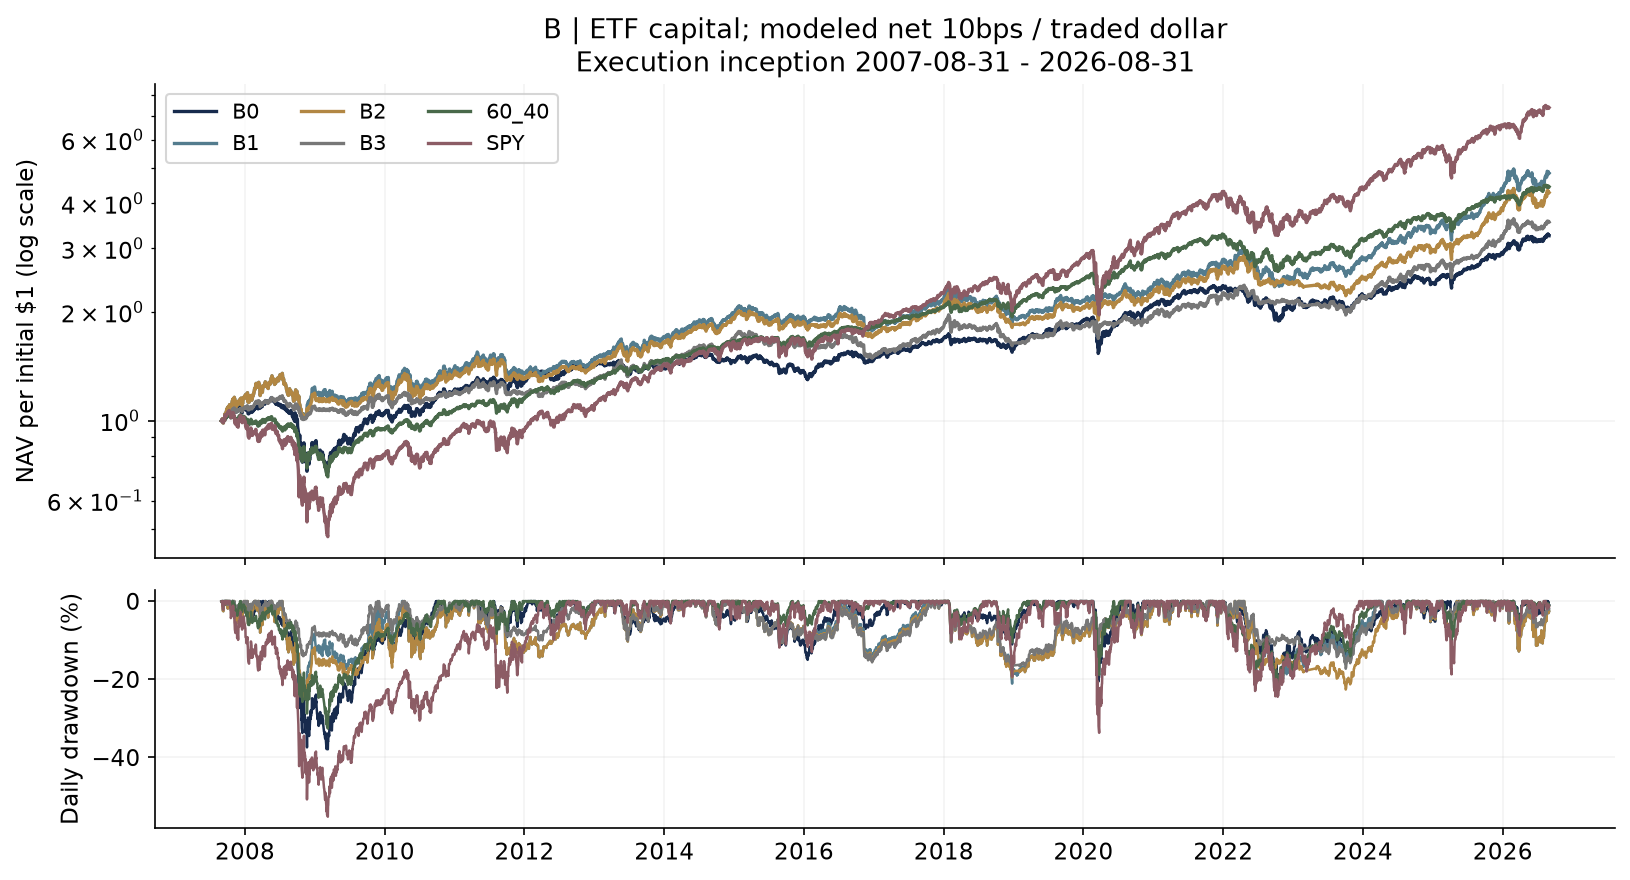

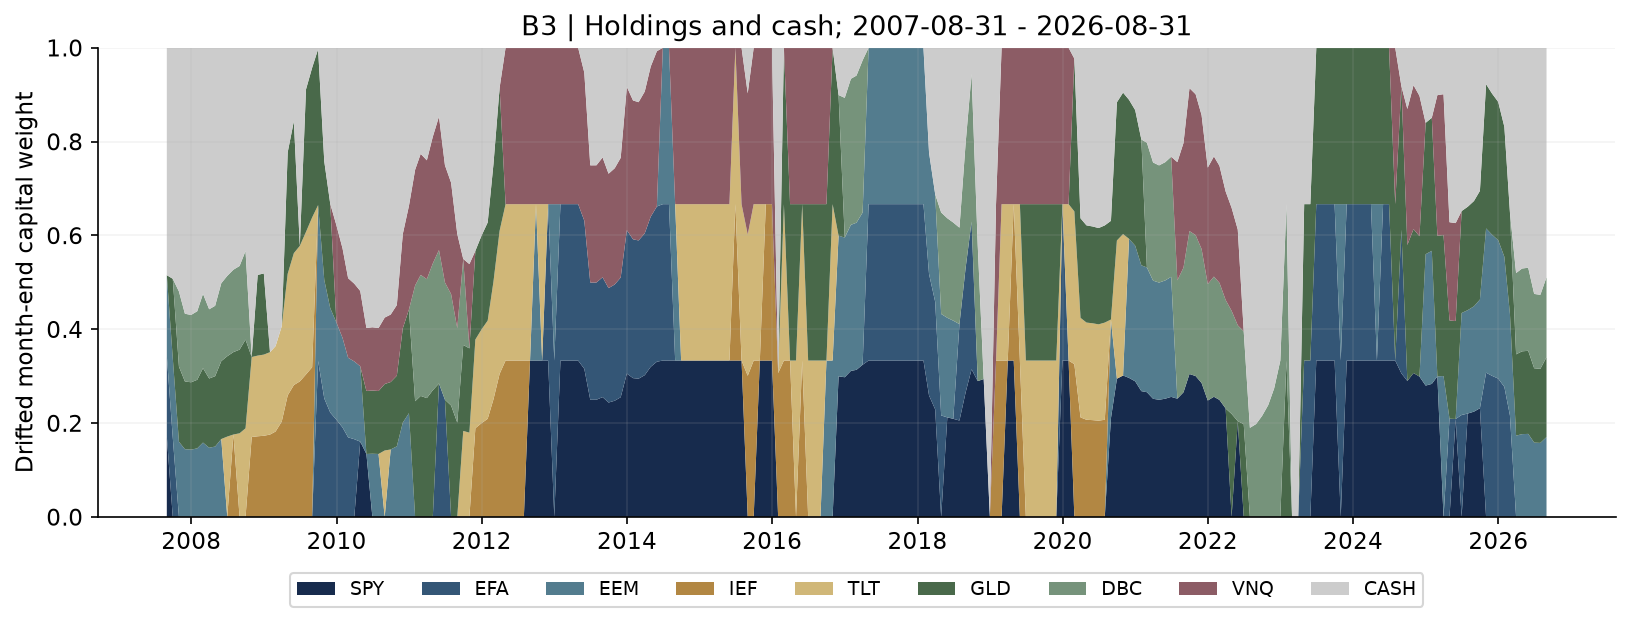

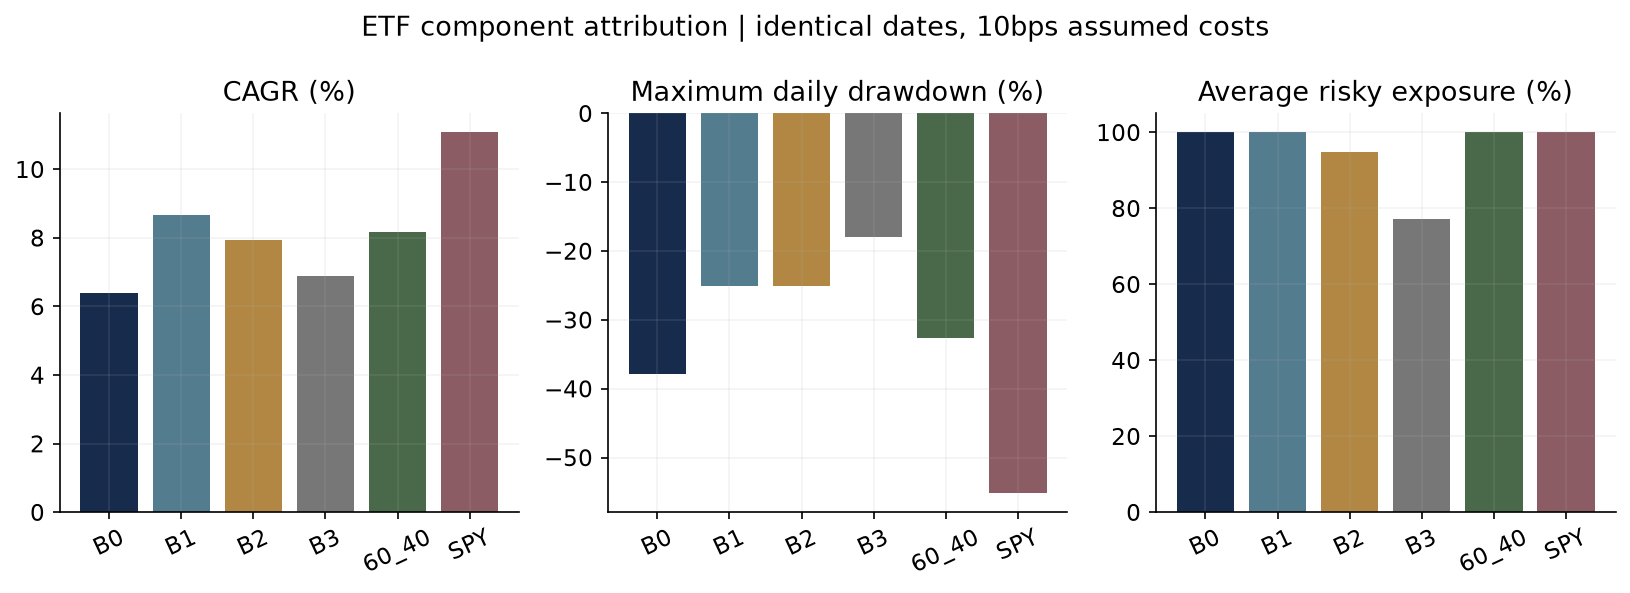

In [6]:
display(Image(filename=str(ROOT/'outputs/figures/B_nav_drawdown.png')))
display(Image(filename=str(ROOT/'outputs/figures/B_allocations.png')))
display(Image(filename=str(ROOT/'outputs/figures/B_components.png')))

## Historical validation and paired uncertainty
Development to 2013, validation 2014–2019, historical holdout from 2020. Preserve earlier signal history. This public historical holdout is inspected, not pristine future evidence. Six-month paired moving-block bootstrap, 1000 draws, seed9339; intervals crossing zero do not establish advantage.

In [7]:
display(pd.read_csv(ROOT/'outputs/tables/performance.csv').query("sample=='historical_holdout' and prototype=='B'")[[ 'variant','CAGR','Sharpe','max_daily_drawdown','average_exposure']])
display(pd.read_csv(ROOT/'outputs/tables/bootstrap.csv').query("prototype=='B' and sample=='full'"))
display(pd.read_csv(ROOT/'outputs/tables/sensitivities.csv').query("prototype=='B' and component=='B3'")[[ 'variant','start','CAGR','Sharpe','max_daily_drawdown']])

,variant,CAGR,Sharpe,max_daily_drawdown,average_exposure
19,B0,0.08512,0.52719,-0.20677,1.00000
23,B1,0.12967,0.80375,-0.21568,1.00000
27,B2,0.11611,0.73954,-0.22642,0.90773
31,SPY,0.15514,0.76802,-0.33717,1.00000
35,60_40,0.09317,0.58757,-0.21298,1.00000
39,CASH,0.02926,NaN,0.00000,0.00000
43,B3,0.10459,0.80501,-0.17317,0.73571


,prototype,left,right,sample,n_months,block_months,replications,annual_excess_mean_difference,annual_excess_mean_difference_low,annual_excess_mean_difference_high,Sharpe_difference,Sharpe_difference_low,Sharpe_difference_high
8,B,B1,B0,full,228,6,1000,0.02297,-0.02505,0.06206,0.11957,-0.29291,0.46115
10,B,B2,B1,full,228,6,1000,-0.00709,-0.01882,0.00186,-0.03660,-0.12796,0.03814
12,B,B3,B2,full,228,6,1000,-0.01326,-0.02510,0.00411,0.04352,-0.06125,0.16253
14,B,B2,B0,full,228,6,1000,0.01588,-0.03261,0.05513,0.08297,-0.32096,0.42679
16,B,B2,60_40,full,228,6,1000,0.00104,-0.04886,0.03643,-0.14914,-0.61375,0.19607
18,B,B3,60_40,full,228,6,1000,-0.01222,-0.05355,0.02587,-0.10562,-0.59792,0.27882


,variant,start,CAGR,Sharpe,max_daily_drawdown
27,primary,2007-10-31,0.06527,0.57912,-0.17911
29,lookback_months_6,2007-10-31,0.07388,0.69112,-0.21601
31,lookback_months_9,2007-10-31,0.08245,0.83345,-0.14272
33,top_k_2,2007-10-31,0.06439,0.54534,-0.19714
35,top_k_4,2007-10-31,0.06387,0.59390,-0.15450
37,skip_latest_month_True,2007-10-31,0.06457,0.56233,-0.24734
39,cost_bps_per_traded_dollar_0,2007-10-31,0.06861,0.61459,-0.17695
41,cost_bps_per_traded_dollar_5,2007-10-31,0.06694,0.59684,-0.17803
43,cost_bps_per_traded_dollar_25,2007-10-31,0.06026,0.52612,-0.18235
45,cost_bps_per_traded_dollar_50,2007-10-31,0.05196,0.43844,-0.18919


## Capacity is provisional
Dollar ADV is mean(provider Close times share Volume) over 20 sessions through snapshot, not adjusted price. Participation uses evolving scenario NAV times absolute risky trade weights. No actual auction capacity or spread measurement is claimed. The evolving10m scenario breaches illustrative small-participation constraints in some instruments.

In [8]:
display(pd.read_csv(ROOT/'outputs/tables/capacity_summary.csv').query("variant=='B3' and initial_aum==10000000"))
display(pd.read_csv(ROOT/'outputs/tables/capacity_trades.csv').query("variant=='B3' and ticker=='DBC' and initial_aum==10000000").nlargest(3,'participation'))

,variant,ticker,initial_aum,maximum,p95,fraction_above_1pct,fraction_above_5pct
25,B3,DBC,10000000,0.19174,0.03288,0.08734,0.03930
28,B3,EEM,10000000,0.00728,0.00258,0.00000,0.00000
31,B3,EFA,10000000,0.00984,0.00430,0.00000,0.00000
34,B3,GLD,10000000,0.00779,0.00324,0.00000,0.00000
37,B3,IEF,10000000,0.07717,0.02246,0.07860,0.01747
40,B3,SPY,10000000,0.00031,0.00019,0.00000,0.00000
43,B3,TLT,10000000,0.01046,0.00530,0.00873,0.00000
46,B3,VNQ,10000000,0.03111,0.01923,0.09170,0.00000


,variant,ticker,execution_date,signal_date,initial_aum,pretrade_aum,trade_dollars,ADV20,participation,illustrative_max_aum_1pct_ADV,illustrative_max_aum_5pct_ADV
5563,B3,DBC,2007-10-31,2007-10-30,10000000,10782320.04839,1727342.44311,9008893.75982,0.19174,562348.10988,2811740.54941
9979,B3,DBC,2023-02-28,2023-02-27,10000000,20821571.36299,6846418.54859,37619167.97363,0.18199,1144087.50359,5720437.51796
10867,B3,DBC,2026-03-31,2026-03-30,10000000,34041472.40286,5899366.41262,44155504.92436,0.13360,2547931.92554,12739659.62771


## Research-stage recommendation and sources
B3 fits a transparent risk-limited ETF design; keep B1 as a serious higher-return comparator and 60/40 as a competitive benchmark. Validate independent prices/actions, consolidated/auction liquidity and prospective time-stamped decisions before any mandate. Preserve holdings and escalate if data/rebalance fails. No trades or submission. Lecture slides22–44; Asness etal2014; Kolanovic–Wei2015 pp19–20,59–60; Baltas–Kosowski supplied2013 section3. Source map and report provide precise references, Q&A, costs and limitations.

### Additional data QA after execution
Yahoo Close is historical split-normalized, not original pre-split transaction price. All split events and first/last dividends are internally reconciled. Targeted issuer distribution comparisons show rounding discrepancies; a June2026 EEM month-end comparison differs about2.14bps. No input repairs or strategy changes. Volume normalization and consolidated/auction scope remain uncertified: capacity is a vendor dollar-volume proxy. See research/corporate_actions.md and outputs/audits/independent_provider_checks.csv.